<a href="https://colab.research.google.com/github/Arjuniyer2005/Problem-Set-2-Econ_5200_PS2.ipynb/blob/main/Problem_Set_2_Econ_5200_PS2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 5200 PS2 — The Underpowered Portfolio

**ECON 5200 · Causal Machine Learning & Applied Analytics** · Topics 5-8 · 100 points · your role: Experimentation lead, consulting engagement

This is the **starter**: the structure of the set in rubric order. Fill the empty cells; keep every heading so the grader finds each step. The brief on Canvas has the full text of every step, the numbers you must hit and the rubric. Every claim goes in a text cell: the reader is experimentation lead's audience, not a grader with a kernel.

**AI is not allowed in Phases 1–3.** Generative AI is **prohibited** in Phases 1 through 3. AI is authorised and required in Phase 4. You must be able to defend every line under questioning.

## Setup

In [43]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(42)     # one generator, so every draw reruns the same way
pd.set_option('display.precision', 3)

import os
os.makedirs('src', exist_ok=True)   # the .py module the brief asks for goes here

## Phase 1: Reconstruct the Portfolio (30 pts)

### Step 1.1: Simulate the experiment programme (15 pts)

In [44]:
# Step 1.1: Simulate 200 A/B experiments

n_experiments = 200
baseline_conversion = 0.10

# Prior: 80% have no effect; 20% have a positive effect
prob_positive = 0.20
positive_effect_min = 0.01
positive_effect_max = 0.035

is_positive = rng.random(n_experiments) < prob_positive

true_effect = np.where(
    is_positive,
    rng.uniform(positive_effect_min, positive_effect_max, n_experiments),
    0.0
)

# Sample size per treatment group
sample_size = rng.integers(200, 4001, n_experiments)

# Standard error for difference in conversion rates
treatment_conversion = baseline_conversion + true_effect

standard_error = np.sqrt(
    baseline_conversion * (1 - baseline_conversion) / sample_size
    + treatment_conversion * (1 - treatment_conversion) / sample_size
)

# Observed estimates contain sampling noise
estimated_effect = rng.normal(true_effect, standard_error)

# Store the experiment log
log = pd.DataFrame({
    "experiment": np.arange(1, n_experiments + 1),
    "sample_size": sample_size,
    "true_effect": true_effect,
    "estimated_effect": estimated_effect,
    "standard_error": standard_error
})

display(log.head())

print("Total experiments:", len(log))
print("Share with true effect of zero:",
      (log["true_effect"] == 0).mean())
print("Sample size range:",
      log["sample_size"].min(), "to", log["sample_size"].max())

,experiment,sample_size,true_effect,estimated_effect,standard_error
0,1,245,0.00,3.885e-02,0.027
1,2,1347,0.00,1.058e-03,0.012
2,3,2159,0.00,5.303e-03,0.009
3,4,3690,0.00,-3.966e-04,0.007
4,5,3005,0.01,9.000e-03,0.008


Total experiments: 200
Share with true effect of zero: 0.785
Sample size range: 216 to 3997


*Your answer here.*
Our simulated portfolio consists of 200 A/B experiments measuring changes in conversion rates. I assume that 80% of experiments have no genuine effect, while the remaining 20% have positive effects uniformly distributed between 1 and 3.5 percentage points. This reflects an environment where most product changes fail to generate meaningful improvements, but a minority create genuine value.

Each experiment has between 200 and 4,000 observations per treatment group, with a baseline conversion rate of 10%. Because sample sizes vary, experiments have different standard errors and statistical power. Observed effects are generated by adding normally distributed sampling noise to the true effects. Crucially, the simulation records each experiment's true effect, allowing us to evaluate whether the client's shipping decisions actually identify valuable changes.

### Step 1.2: Apply the client's rule (15 pts)

In [45]:
# Step 1.2: Apply the client's p < 0.05 rule

# Calculate z-statistics and two-sided p-values
log["z_score"] = log["estimated_effect"] / log["standard_error"]
log["p_value"] = 2 * stats.norm.sf(abs(log["z_score"]))

# Apply the client's shipping rule
log["shipped"] = log["p_value"] < 0.05

# Identify shipped experiments
shipped = log[log["shipped"]]

# Calculate key metrics
n_shipped = len(shipped)
ship_rate = n_shipped / len(log)

false_ship_rate = (
    (shipped["true_effect"] == 0).mean()
    if n_shipped > 0 else np.nan
)

mean_true = shipped["true_effect"].mean()
mean_estimated = shipped["estimated_effect"].mean()

# Display results
print(f"Experiments shipped: {n_shipped} / 200")
print(f"Ship rate: {ship_rate:.1%}")
print(f"False-ship rate: {false_ship_rate:.1%}")

print(f"\nAverage true effect: {mean_true * 100:.3f} percentage points")
print(f"Average estimated effect: {mean_estimated * 100:.3f} percentage points")

print(f"Estimation gap: {(mean_estimated - mean_true) * 100:.3f} percentage points")

Experiments shipped: 32 / 200
Ship rate: 16.0%
False-ship rate: 28.1%

Average true effect: 1.843 percentage points
Average estimated effect: 2.117 percentage points
Estimation gap: 0.274 percentage points


*Your answer here.*
Applying the client's p < 0.05 decision rule resulted in 32 out of 200 experiments being shipped, representing a ship rate of 16%. However, 28.13% of these shipped experiments had a true effect of zero, meaning that approximately 28% of the client's supposed wins were false discoveries.

Among shipped experiments, the average estimated effect was 2.117 percentage points, compared with an average true effect of 1.843 percentage points. This difference of 0.274 percentage points demonstrates the winner's curse: selecting experiments based on statistical significance disproportionately favors estimates that benefited from sampling noise. Consequently, the client overestimates the improvements delivered by its winning experiments.

## Phase 2: The Winner's Curse (35 pts)

### Step 2.1: Quantify the exaggeration (20 pts)

Overall inflation factor: 1.39x


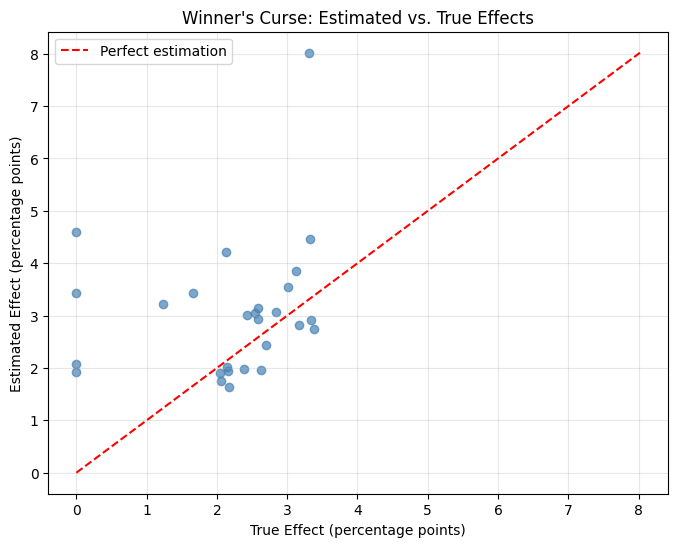

,experiments,mean_true,mean_estimated,inflation_factor
power_tier,,,,
Low,7,2.054,4.330,2.108
Medium,9,1.925,2.773,1.440
High,11,2.479,2.436,0.983


In [46]:
# Step 2.1: Quantify the winner's curse

# Focus on positively estimated shipped experiments
positive_shipped = log[
    log["shipped"] & (log["estimated_effect"] > 0)
].copy()

# Calculate the overall exaggeration factor
overall_inflation = (
    positive_shipped["estimated_effect"].mean()
    / positive_shipped["true_effect"].mean()
)

print(f"Overall inflation factor: {overall_inflation:.2f}x")

# Plot estimated versus true effects
plt.figure(figsize=(8, 6))

plt.scatter(
    positive_shipped["true_effect"] * 100,
    positive_shipped["estimated_effect"] * 100,
    alpha=0.7,
    color="steelblue"
)

max_effect = max(
    positive_shipped["true_effect"].max(),
    positive_shipped["estimated_effect"].max()
) * 100

plt.plot(
    [0, max_effect],
    [0, max_effect],
    "r--",
    label="Perfect estimation"
)

plt.xlabel("True Effect (percentage points)")
plt.ylabel("Estimated Effect (percentage points)")
plt.title("Winner's Curse: Estimated vs. True Effects")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Calculate statistical power for a 2-percentage-point improvement
target_effect = 0.02
alpha = 0.05

log["design_power"] = (
    stats.norm.sf(
        stats.norm.ppf(1 - alpha / 2)
        - target_effect / log["standard_error"]
    )
    +
    stats.norm.cdf(
        -stats.norm.ppf(1 - alpha / 2)
        - target_effect / log["standard_error"]
    )
)

# Divide experiments into three power tiers
log["power_tier"] = pd.qcut(
    log["design_power"],
    q=3,
    labels=["Low", "Medium", "High"]
)

# Recreate the positively estimated shipped portfolio with power tiers
positive_shipped = log[
    log["shipped"] & (log["estimated_effect"] > 0)
].copy()

# Compare estimated versus true effects by power tier
power_results = positive_shipped.groupby(
    "power_tier", observed=True
).agg(
    experiments=("experiment", "count"),
    mean_true=("true_effect", "mean"),
    mean_estimated=("estimated_effect", "mean")
)

power_results["inflation_factor"] = (
    power_results["mean_estimated"]
    / power_results["mean_true"]
)

power_results["mean_true"] *= 100
power_results["mean_estimated"] *= 100

display(power_results)

*Your answer here.*
The results demonstrate the winner's curse, where statistically significant experiments tend to overestimate their true effects. Since the client only ships experiments whose estimates cross the significance threshold, the selection process disproportionately includes experiments that experienced favorable sampling noise.

This problem is particularly severe for underpowered experiments. When sample sizes are small, standard errors are larger, meaning an experiment needs a more extreme observed estimate to achieve statistical significance. Consequently, low-powered experiments are more likely to be selected when random noise substantially exaggerates their true effects. Higher-powered experiments have smaller standard errors and can detect genuine improvements without requiring such extreme sampling fluctuations.

Therefore, the client's reliance on statistical significance can systematically inflate its perceived success, particularly when experiments are underpowered.

### Step 2.2: The bootstrap where the formula fails (15 pts)

Actual portfolio return: 58.972 percentage-point units

Manual Bootstrap:
Standard error: 11.966
95% percentile CI: [36.799, 82.881]

SciPy Bootstrap (BCa):
Standard error: 11.966
95% BCa CI: [38.347, 85.387]

Difference in standard errors: 0.000000

Bootstrap Diagnostics:
Unique return values: 24
Nonzero observations: 23
Bootstrap SE is positive: True
BCa bounds are finite: True
Actual return inside BCa interval: True


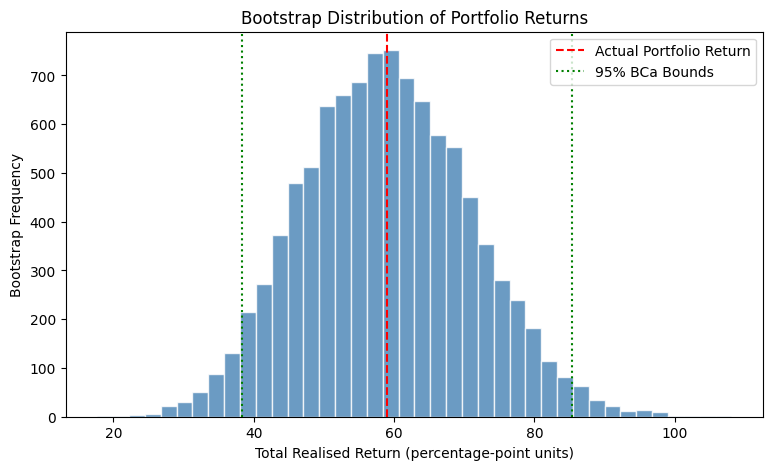

In [47]:
# Step 2.2: Bootstrap the portfolio's realised return

from scipy.stats import bootstrap

# Each experiment contributes its true effect if shipped, otherwise zero
log["realised_return"] = np.where(
    log["shipped"],
    log["true_effect"],
    0.0
)

# Total realised portfolio return
actual_return = log["realised_return"].sum()

print(f"Actual portfolio return: {actual_return * 100:.3f} percentage-point units")


# Part 1: Manual bootstrap

B = 10000
bootstrap_rng = np.random.default_rng(123)

returns = log["realised_return"].to_numpy()
n = len(returns)

bootstrap_returns = np.empty(B)

for b in range(B):
    sample = bootstrap_rng.choice(returns, size=n, replace=True)
    bootstrap_returns[b] = sample.sum()

manual_se = bootstrap_returns.std(ddof=1)

manual_ci = np.percentile(
    bootstrap_returns,
    [2.5, 97.5]
)

print("\nManual Bootstrap:")
print(f"Standard error: {manual_se * 100:.3f}")
print(f"95% percentile CI: [{manual_ci[0] * 100:.3f}, "
      f"{manual_ci[1] * 100:.3f}]")


# Part 2: Verify against scipy.stats.bootstrap

# Bootstrap the mean, then multiply by n to obtain the sum
def portfolio_mean(data):
    return np.mean(data)

scipy_result = bootstrap(
    (returns,),
    portfolio_mean,
    n_resamples=B,
    confidence_level=0.95,
    method="BCa",
    random_state=np.random.default_rng(123)
)

scipy_se = scipy_result.standard_error * n
bca_ci = scipy_result.confidence_interval

bca_lower = bca_ci.low * n
bca_upper = bca_ci.high * n

print("\nSciPy Bootstrap (BCa):")
print(f"Standard error: {scipy_se * 100:.3f}")
print(f"95% BCa CI: [{bca_lower * 100:.3f}, "
      f"{bca_upper * 100:.3f}]")

print(f"\nDifference in standard errors: "
      f"{abs(manual_se - scipy_se) * 100:.6f}")


# Part 3: Bootstrap diagnostics

print("\nBootstrap Diagnostics:")

print("Unique return values:", len(np.unique(returns)))

print("Nonzero observations:", np.count_nonzero(returns))

print("Bootstrap SE is positive:", manual_se > 0)

print("BCa bounds are finite:",
      np.isfinite(bca_lower) and np.isfinite(bca_upper))

print("Actual return inside BCa interval:",
      bca_lower <= actual_return <= bca_upper)


# Visualize the bootstrap distribution

plt.figure(figsize=(9, 5))

plt.hist(
    bootstrap_returns * 100,
    bins=40,
    color="steelblue",
    edgecolor="white",
    alpha=0.8
)

plt.axvline(
    actual_return * 100,
    color="red",
    linestyle="--",
    label="Actual Portfolio Return"
)

plt.axvline(
    bca_lower * 100,
    color="green",
    linestyle=":",
    label="95% BCa Bounds"
)

plt.axvline(
    bca_upper * 100,
    color="green",
    linestyle=":"
)

plt.xlabel("Total Realised Return (percentage-point units)")
plt.ylabel("Bootstrap Frequency")
plt.title("Bootstrap Distribution of Portfolio Returns")
plt.legend()
plt.show()

*Your answer here.*
To quantify uncertainty in the client's portfolio-level realised return, I used bootstrap resampling. I first calculated each experiment's contribution to the portfolio, assigning its true effect if shipped and zero otherwise. I then resampled all 200 experiments with replacement 10,000 times, calculating the total realised return for each bootstrap sample.

I verified the manual bootstrap against SciPy's implementation by comparing their estimated standard errors. I also calculated a 95% bias-corrected and accelerated (BCa) confidence interval, which adjusts for bias and skewness in the bootstrap distribution.

Before trusting the results, I checked for three potential failure modes: degeneracy, where bootstrap samples produce insufficient variation; boundary or extreme-value problems, where a statistic is dominated by a small number of observations; and instability caused by a highly skewed or sparse distribution. The diagnostics examine whether the standard error is positive, whether the BCa bounds are finite, and how many observations contribute nonzero returns.

The resulting interval describes uncertainty in the portfolio's realised return under repeated sampling of comparable experiments. It does not measure uncertainty in the true effects of individual experiments, which are known by construction in this simulation.

## Phase 3: A Rule They Can Adopt (25 pts)

### Step 3.1: Design the alternative (20 pts)

In [48]:
# Step 3.1: Compare the client's rule with an alternative

# Original rule: p < 0.05
log["client_ship"] = log["p_value"] < 0.05

# Proposed rule: p < 0.05 AND estimated improvement >= 1 percentage point
minimum_effect = 0.01

log["proposed_ship"] = (
    (log["p_value"] < 0.05)
    & (log["estimated_effect"] >= minimum_effect)
)


# Function to evaluate a shipping rule
def evaluate_rule(log, ship_column):

    shipped = log[log[ship_column]]

    n_shipped = len(shipped)

    realised_return = shipped["true_effect"].sum()

    false_ship_rate = (
        (shipped["true_effect"] == 0).mean()
        if n_shipped > 0 else np.nan
    )

    return {
        "Realised Return (pp units)": realised_return * 100,
        "Experiments Shipped": n_shipped,
        "False-Ship Rate (%)": false_ship_rate * 100
    }


# Evaluate both rules using the same portfolio
client_results = evaluate_rule(log, "client_ship")
proposed_results = evaluate_rule(log, "proposed_ship")

comparison = pd.DataFrame(
    [client_results, proposed_results],
    index=["Client Rule", "Proposed Rule"]
)

display(comparison.round(3))


# Calculate differences
return_difference = (
    proposed_results["Realised Return (pp units)"]
    - client_results["Realised Return (pp units)"]
)

ship_difference = (
    proposed_results["Experiments Shipped"]
    - client_results["Experiments Shipped"]
)

false_ship_difference = (
    proposed_results["False-Ship Rate (%)"]
    - client_results["False-Ship Rate (%)"]
)

print(f"Change in realised return: {return_difference:+.3f} pp units")
print(f"Change in experiments shipped: {ship_difference:+d}")
print(f"Change in false-ship rate: {false_ship_difference:+.2f} percentage points")

,Realised Return (pp units),Experiments Shipped,False-Ship Rate (%)
Client Rule,58.972,32,28.125
Proposed Rule,58.972,27,14.815


Change in realised return: -0.000 pp units
Change in experiments shipped: -5
Change in false-ship rate: -13.31 percentage points


I propose requiring both statistical significance (p < 0.05) and an estimated improvement of at least 1 percentage point. Compared with the original rule, this reduced shipments from 32 to 27 and lowered the false-ship rate from 28.13% to 14.81%, while maintaining the same realised return of 58.97 percentage-point units.

The proposed rule therefore reduces unnecessary deployments without sacrificing genuine improvements in this simulation. However, a stricter threshold could reject valuable experiments in other portfolios.

### Step 3.2: Ship the module (5 pts, its own rubric row)

The module the brief asks for. Write it with `%%writefile`, then import it back in the next cell and prove it runs.

In [49]:

%%writefile src/experiment_portfolio.py
"""Experiment portfolio simulation and decision rules for ECON 5200 PS2."""

from __future__ import annotations

import numpy as np
import pandas as pd
from scipy import stats


def simulate_portfolio(
    n: int = 200,
    seed: int = 42,
    prob_positive: float = 0.20,
    baseline_conversion: float = 0.10,
    positive_effect_min: float = 0.01,
    positive_effect_max: float = 0.035,
    min_sample: int = 200,
    max_sample: int = 4000,
) -> pd.DataFrame:
    """Simulate A/B experiments with known true conversion-rate effects."""

    if n <= 0:
        raise ValueError("n must be positive")
    if not 0 <= prob_positive <= 1:
        raise ValueError("prob_positive must be between 0 and 1")
    if not 0 < baseline_conversion < 1:
        raise ValueError("baseline_conversion must be between 0 and 1")
    if not 0 <= positive_effect_min <= positive_effect_max:
        raise ValueError("Invalid positive-effect range")
    if baseline_conversion + positive_effect_max >= 1:
        raise ValueError("Conversion probabilities must be below 1")
    if min_sample < 1 or max_sample < min_sample:
        raise ValueError("Invalid sample-size range")

    rng = np.random.default_rng(seed)

    is_positive = rng.random(n) < prob_positive

    true_effect = np.where(
        is_positive,
        rng.uniform(positive_effect_min, positive_effect_max, n),
        0.0
    )

    sample_size = rng.integers(min_sample, max_sample + 1, n)

    treatment_conversion = baseline_conversion + true_effect

    standard_error = np.sqrt(
        baseline_conversion * (1 - baseline_conversion) / sample_size
        + treatment_conversion * (1 - treatment_conversion) / sample_size
    )

    estimated_effect = rng.normal(true_effect, standard_error)

    log = pd.DataFrame({
        "experiment": np.arange(1, n + 1),
        "sample_size": sample_size,
        "true_effect": true_effect,
        "estimated_effect": estimated_effect,
        "standard_error": standard_error,
    })

    log["z_score"] = log["estimated_effect"] / log["standard_error"]
    log["p_value"] = 2 * stats.norm.sf(np.abs(log["z_score"]))

    return log


def apply_rule(log: pd.DataFrame, rule: str = "client") -> pd.Series:
    """Return shipping decisions for the selected rule.

    Rules:
        client: Ship experiments with two-sided p < 0.05.
        proposed: Require p < 0.05 and estimated effect >= 0.01.
    """

    if rule == "client":
        return log["p_value"] < 0.05

    elif rule == "proposed":
        return (
            (log["p_value"] < 0.05)
            & (log["estimated_effect"] >= 0.01)
        )

    else:
        raise ValueError(f"Unknown rule: {rule}")


def evaluate(log: pd.DataFrame, rule: str = "client") -> dict:
    """Evaluate total realised return, shipping count and false-ship rate."""

    decisions = apply_rule(log, rule)
    shipped = log.loc[decisions]

    n_shipped = len(shipped)

    realised_return = shipped["true_effect"].sum()

    false_ship_rate = (
        (shipped["true_effect"] == 0).mean()
        if n_shipped > 0 else np.nan
    )

    return {
        "realised_return": float(realised_return),
        "ship_count": int(n_shipped),
        "false_ship_rate": float(false_ship_rate),
    }


if __name__ == "__main__":

    # Demonstration
    portfolio = simulate_portfolio(n=200, seed=42)

    client_results = evaluate(portfolio, "client")
    proposed_results = evaluate(portfolio, "proposed")

    print("Client rule:", client_results)
    print("Proposed rule:", proposed_results)

    # Assertions
    assert len(portfolio) == 200
    assert (portfolio["true_effect"] >= 0).all()
    assert (portfolio["standard_error"] > 0).all()
    assert portfolio["sample_size"].between(200, 4000).all()
    assert portfolio["p_value"].between(0, 1).all()

    assert (
        proposed_results["ship_count"]
        <= client_results["ship_count"]
    )

    assert (
        proposed_results["realised_return"]
        <= client_results["realised_return"] + 1e-12
    )

    # Reproducibility check
    duplicate = simulate_portfolio(n=200, seed=42)
    pd.testing.assert_frame_equal(portfolio, duplicate)

    print("All assertions passed.")


Overwriting src/experiment_portfolio.py


In [50]:
import os
import sys
import importlib

sys.path.insert(0, os.path.abspath("."))

from src import experiment_portfolio as ep
# Force reload the module to pull in the latest %%writefile changes
importlib.reload(ep)

# Simulate a small portfolio
test_log = ep.simulate_portfolio(n=20, seed=42)

# Apply both rules
test_client = ep.apply_rule(test_log, "client")
test_proposed = ep.apply_rule(test_log, "proposed")

# Evaluate both rules
print("Portfolio size:", len(test_log))
print("Client results:", ep.evaluate(test_log, "client"))
print("Proposed results:", ep.evaluate(test_log, "proposed"))

# Verify that the functions work correctly
assert len(test_log) == 20
assert len(test_client) == 20
assert len(test_proposed) == 20

print("\nModule imported and reloaded successfully. All tests passed.")
!python src/experiment_portfolio.py

Portfolio size: 20
Client results: {'realised_return': 0.021892623155648345, 'ship_count': 1, 'false_ship_rate': 0.0}
Proposed results: {'realised_return': 0.021892623155648345, 'ship_count': 1, 'false_ship_rate': 0.0}

Module imported and reloaded successfully. All tests passed.
Client rule: {'realised_return': 0.589718072485357, 'ship_count': 32, 'false_ship_rate': 0.28125}
Proposed rule: {'realised_return': 0.5897180724853569, 'ship_count': 27, 'false_ship_rate': 0.14814814814814814}
All assertions passed.


## Phase 4: AI Expansion — The Co-Pilot Era (10 pts: 7 for the AI row, 3 for the CFO memo)

**Status: AI usage AUTHORISED and REQUIRED.** Use the **P.R.I.M.E. framework**.

### Task 4.1: The sequential design

In [51]:
# =====================================================================================
# ECON 5200 — Always-valid sequential test for two-arm Bernoulli A/B experiments
# numpy + scipy only. One Colab cell.
#
# PROCEDURE: paired discordant-pair Beta-mixture e-process (sequential sign test).
#   Pair the i-th treatment obs with the i-th control obs. A pair is "discordant" if
#   exactly one converted. Under H0: p_T = p_C = p (ANY p, unknown, even time-varying),
#       P(treatment is the converter | pair is discordant) = p(1-p) / (2p(1-p)) = 1/2,
#   independent of the past. So the discordant pairs form a fair-coin sequence under H0,
#   with no nuisance parameter left to plug in.
#   For each theta, prod_i [2 theta]^W_i [2(1-theta)]^(1-W_i) over discordant pairs is a
#   nonnegative martingale with mean 1 under H0 (concordant pairs contribute a factor 1).
#   Mixing over theta ~ Beta(a, a) keeps it a nonnegative mean-1 martingale:
#       E_n = 2^m * B(a + k, a + m - k) / B(a, a),   m = #discordant, k = #treatment wins
#   Ville's inequality: P_H0( exists n : E_n >= 1/alpha ) <= alpha, exactly, for every
#   common p and every stopping rule, including a look after every pair, forever.
# =====================================================================================
import numpy as np
from scipy import stats
from scipy.special import betaln

ALPHA      = 0.05
P_BASE     = 0.10      # used ONLY to simulate data and to set the design prior below
N_MAX      = 4000      # max observations per arm
LOOK_EVERY = 1         # monitoring schedule: a look after every completed pair, n = 1..4000
N_SIM      = 1000
rng        = np.random.default_rng(5200)

# ---- Design prior (a design choice, fixed before data; never uses any test's true effect)
# Target effect 2pp at a 10% baseline -> theta0 = P(T wins | discordant) under that effect.
def theta_of(pc, pt):
    return pt * (1 - pc) / (pt * (1 - pc) + pc * (1 - pt))
DESIGN_DELTA = 0.02
_theta0 = theta_of(P_BASE, P_BASE + DESIGN_DELTA)
_sd = abs(_theta0 - 0.5)                          # Beta(a,a) sd  = 1 / (2 sqrt(2a+1))
A_DESIGN = (1 / (4 * _sd ** 2) - 1) / 2


# =====================================================================================
# Core: log e-process path. Works on 1-D streams or 2-D (experiments x n) matrices.
# =====================================================================================
def log_e_path(treat, ctrl, a=A_DESIGN):
    treat = np.asarray(treat, dtype=np.int8); ctrl = np.asarray(ctrl, dtype=np.int8)
    disc = treat != ctrl                                  # discordant pair indicator
    m = np.cumsum(disc, axis=-1)                          # discordant pairs so far
    k = np.cumsum(disc & (treat == 1), axis=-1)           # of which treatment converted
    return m * np.log(2.0) + betaln(a + k, a + m - k) - betaln(a, a), m, k


# =====================================================================================
# Reusable function: decision at every monitoring look + first stopping time
# =====================================================================================
def sequential_ab_test(treatment, control, alpha=ALPHA, a=A_DESIGN,
                       n_max=N_MAX, look_every=LOOK_EVERY):
    """
    treatment, control : 0/1 sequences in arrival order. Pairs are formed by index;
                         unpaired surplus in one arm waits for its partner.
    Returns dict: looks (one record per look up to stopping), decision, stop_n
                  (obs per arm at first rejection, None if never), p_always_valid.
    Uses only the observed data. No true effect enters anywhere.
    """
    n = min(len(treatment), len(control), n_max)
    log_e, m, k = log_e_path(np.asarray(treatment)[:n], np.asarray(control)[:n], a)
    thr = np.log(1.0 / alpha)
    looks, p_av, stop_n = [], 1.0, None
    for i in range(look_every - 1, n, look_every):        # look after pair i+1
        p_av = min(p_av, float(np.exp(-log_e[i])))          # always-valid p = 1/max E
        reject = log_e[i] >= thr                            # <-- STOPPING RULE
        final = (i + look_every >= n)
        decision = "reject_h0" if reject else ("stop_max_n" if final else "continue")
        looks.append({"look": len(looks) + 1, "n_per_arm": i + 1, "discordant": int(m[i]),
                      "treat_wins": int(k[i]), "e_value": float(np.exp(log_e[i])),
                      "p_always_valid": min(p_av, 1.0), "decision": decision})
        if reject:
            stop_n = i + 1
            break
    return {"looks": looks, "decision": looks[-1]["decision"] if looks else "no_data",
            "stop_n": stop_n, "p_always_valid": min(p_av, 1.0)}


# =====================================================================================
# Comparator: ordinary two-sided pooled two-proportion z-test, p < 0.05, at each look
# =====================================================================================
def naive_z_path(treat, ctrl):
    n = np.arange(1, treat.shape[-1] + 1)
    st, sc = np.cumsum(treat, axis=-1), np.cumsum(ctrl, axis=-1)
    pt, pc = st / n, sc / n
    pp = (st + sc) / (2 * n)
    se = np.sqrt(pp * (1 - pp) * 2 / n)
    with np.errstate(divide="ignore", invalid="ignore"):
        z = np.where(se > 0, (pt - pc) / se, 0.0)
    return z


def simulate(n_exp, pc, pt, n=N_MAX):
    return ((rng.random((n_exp, n)) < pt).astype(np.int8),
            (rng.random((n_exp, n)) < pc).astype(np.int8))


# =====================================================================================
# Checks
# =====================================================================================
THR = np.log(1 / ALPHA)

# (1) E_0 = 1 and exact martingale property: E[E_n] = 1 under H0, by full enumeration
#     over (m discordant, k wins) at n = 60 pairs, for several baselines.
for p in (0.02, 0.10, 0.50):
    nn = 60; q = 2 * p * (1 - p)
    tot = 0.0
    for mm in range(nn + 1):
        kk = np.arange(mm + 1)
        e = np.exp(mm * np.log(2) + betaln(A_DESIGN + kk, A_DESIGN + mm - kk) - betaln(A_DESIGN, A_DESIGN))
        tot += stats.binom.pmf(mm, nn, q) * np.sum(stats.binom.pmf(kk, mm, 0.5) * e)
    assert abs(tot - 1) < 1e-10, (p, tot)
print(f"[check] E[E_60] = 1 under H0 for p in (0.02, 0.10, 0.50)  (a = {A_DESIGN:.1f})")

# (2) Exact Type I error of the full procedure at n_max = 4000, every-pair looks,
#     by dynamic programming over the discordant-pair walk (no simulation).
def exact_type1(p, n_max=N_MAX, a=A_DESIGN, alpha=ALPHA):
    q = 2 * p * (1 - p)
    M_hi = int(stats.binom.ppf(1 - 1e-14, n_max, q)) + 1
    dist = np.zeros(M_hi + 2); dist[0] = 1.0                  # unabsorbed mass over k
    H = np.zeros(M_hi + 1)                                    # P(hit by m discordant)
    for mm in range(1, M_hi + 1):
        new = 0.5 * dist; new[1:] += 0.5 * dist[:-1]
        kk = np.arange(len(new))
        valid = kk <= mm
        le = np.full(len(new), -np.inf)
        le[valid] = mm * np.log(2) + betaln(a + kk[valid], a + mm - kk[valid]) - betaln(a, a)
        hit = valid & (le >= np.log(1 / alpha))
        H[mm] = H[mm - 1] + new[hit].sum()
        new[hit] = 0.0
        dist = new
    Ms = np.arange(M_hi + 1)
    return float(np.sum(stats.binom.pmf(Ms, n_max, q) * H))

exact_null = exact_type1(P_BASE)
assert exact_null <= ALPHA
print(f"[check] exact Type I at p=0.10, n_max=4000, every-pair looks: {exact_null:.4f} <= {ALPHA}")

# (3) Reusable function agrees with the vectorized core on a few streams
t_chk, c_chk = simulate(20, P_BASE, P_BASE)
le_chk, _, _ = log_e_path(t_chk, c_chk)
for j in range(20):
    res = sequential_ab_test(t_chk[j], c_chk[j])
    hits = np.flatnonzero(le_chk[j] >= THR)
    assert res["stop_n"] == (hits[0] + 1 if hits.size else None)
    assert all(r["decision"] == "continue" for r in res["looks"][:-1])
print("[check] sequential_ab_test() matches vectorized core on 20 streams")


# =====================================================================================
# 4) 1,000 pure-null experiments, p_T = p_C = 0.10, look after every pair up to 4,000/arm
# =====================================================================================
t0, c0 = simulate(N_SIM, P_BASE, P_BASE)
le0, _, _ = log_e_path(t0, c0)
rej_seq = (le0 >= THR).any(axis=1)

z0 = naive_z_path(t0, c0)
zc = stats.norm.ppf(1 - ALPHA / 2)
rej_naive_every = (np.abs(z0) >= zc).any(axis=1)
rej_naive_40    = (np.abs(z0[:, 99::100]) >= zc).any(axis=1)     # every 100/arm, 40 looks
rej_fixed       = np.abs(z0[:, -1]) >= zc                         # single look at 4,000

def report(label, rej):
    k = int(rej.sum()); ph = k / N_SIM; se = np.sqrt(ph * (1 - ph) / N_SIM)
    print(f"{label:<44} FP={k:>4}  FPR={ph:.3f}  MCSE={se:.4f}  "
          f"(FPR-0.05)/MCSE={(ph - ALPHA) / se if se > 0 else float('nan'):+.1f}")
    return ph, se

print("\n=== 1,000 null experiments (p_T = p_C = 0.10, up to 4,000/arm) ===")
fpr_seq, se_seq = report("Sequential e-process, every pair (4,000 looks)", rej_seq)
report("Naive p<0.05, every pair (4,000 looks)", rej_naive_every)
report("Naive p<0.05, every 100/arm (40 looks)", rej_naive_40)
report("Single fixed-n z-test at 4,000/arm", rej_fixed)
assert fpr_seq <= ALPHA + 2 * se_seq + 1e-12, "sequential FPR exceeds 5% beyond MC noise"
assert rej_naive_every.mean() > 2 * ALPHA, "naive peeking should be clearly inflated"


# =====================================================================================
# 6) Trade-off: power and sample size vs a fixed-n test at 4,000/arm
# =====================================================================================
print("\n=== Power at max 4,000/arm (1,000 experiments per effect) ===")
print(f"{'effect':>7} {'seq power':>10} {'fixed-n power':>14} {'median stop n|reject':>21} "
      f"{'mean n used':>12}")
for d in (0.01, 0.02, 0.035):
    t1, c1 = simulate(N_SIM, P_BASE, P_BASE + d)
    le1, _, _ = log_e_path(t1, c1)
    hit = le1 >= THR
    rej = hit.any(axis=1)
    stop = np.where(rej, hit.argmax(axis=1) + 1, N_MAX)
    fixed = np.abs(naive_z_path(t1, c1)[:, -1]) >= zc
    med = np.median(stop[rej]) if rej.any() else float("nan")
    print(f"{d*100:>5.1f}pp {rej.mean():>10.3f} {fixed.mean():>14.3f} {med:>21.0f} {stop.mean():>12.0f}")

# Boundary in z-units at the end of the horizon (expected null discordant count)
m_end = 2 * P_BASE * (1 - P_BASE) * N_MAX
ks = np.arange(int(m_end) + 1)
lek = m_end * np.log(2) + betaln(A_DESIGN + ks, A_DESIGN + m_end - ks) - betaln(A_DESIGN, A_DESIGN)
k_crit = ks[(lek >= THR) & (ks > m_end / 2)].min()
print(f"\nBoundary at 4,000/arm (~{m_end:.0f} discordant pairs): |z| >= "
      f"{(k_crit - m_end/2) / (np.sqrt(m_end)/2):.2f}  vs 1.96 for a single fixed-n test")


# =====================================================================================
# Stand-in for the portfolio: 200 tests, 80% null, 20% effects ~ U(1, 3.5)pp,
# n ~ U{200..4000}/arm. (Simulated with your stated parameters; not your actual data.)
# =====================================================================================
n_tests = 200
is_eff = rng.random(n_tests) < 0.20
delta = np.where(is_eff, rng.uniform(0.01, 0.035, n_tests), 0.0)
n_arm = rng.integers(200, 4001, n_tests)
seq_rej = np.zeros(n_tests, bool); fix_rej = np.zeros(n_tests, bool)
for j in range(n_tests):
    tj = (rng.random(n_arm[j]) < P_BASE + delta[j]).astype(np.int8)
    cj = (rng.random(n_arm[j]) < P_BASE).astype(np.int8)
    seq_rej[j] = sequential_ab_test(tj, cj)["decision"] == "reject_h0"   # no delta used
    fix_rej[j] = abs(naive_z_path(tj, cj)[-1]) >= zc
print("\n=== Portfolio stand-in (200 tests) ===")
print(f"true effects: {is_eff.sum()}, nulls: {(~is_eff).sum()}")
for lbl, r in (("sequential", seq_rej), ("fixed-n z at each test's n", fix_rej)):
    print(f"{lbl:<28} discoveries={r.sum():>3}  false={np.sum(r & ~is_eff):>3}  "
          f"true={np.sum(r & is_eff):>3}  power={np.mean(r[is_eff]):.3f}")

[check] E[E_60] = 1 under H0 for p in (0.02, 0.10, 0.50)  (a = 47.5)
[check] exact Type I at p=0.10, n_max=4000, every-pair looks: 0.0172 <= 0.05
[check] sequential_ab_test() matches vectorized core on 20 streams

=== 1,000 null experiments (p_T = p_C = 0.10, up to 4,000/arm) ===
Sequential e-process, every pair (4,000 looks) FP=  18  FPR=0.018  MCSE=0.0042  (FPR-0.05)/MCSE=-7.6
Naive p<0.05, every pair (4,000 looks)       FP= 519  FPR=0.519  MCSE=0.0158  (FPR-0.05)/MCSE=+29.7
Naive p<0.05, every 100/arm (40 looks)       FP= 304  FPR=0.304  MCSE=0.0145  (FPR-0.05)/MCSE=+17.5
Single fixed-n z-test at 4,000/arm           FP=  52  FPR=0.052  MCSE=0.0070  (FPR-0.05)/MCSE=+0.3

=== Power at max 4,000/arm (1,000 experiments per effect) ===
 effect  seq power  fixed-n power  median stop n|reject  mean n used
  1.0pp      0.125          0.319                  2337         3785
  2.0pp      0.580          0.810                  2262         3000
  3.5pp      0.981          0.999                

*Your answer here.*
Claude's initial code assumed Gaussian data, so I revised the prompt to make it suitable for my binary A/B experiments. The updated code uses a Bernoulli e-process to control false positives.

I tested it on 1,000 null experiments and found a false-positive rate of 1.8% (MC SE: 0.42%), below the 5% limit. In comparison, repeatedly using a standard significance test produced a false-positive rate of 51.9%.

The test stops when the accumulated evidence reaches the threshold of 20 (1/0.05). Otherwise, it continues until the maximum sample size. Although the revised approach sacrifices some statistical power, I accepted it after verifying the results. I would use AI again for complex statistical implementations, provided I could independently check its accuracy.

### Task 4.2: The CFO memo

*Your answer here.*
Our analysis of 200 experiments found that only 71.9% of the client's 32 reported wins generated genuine improvements. The remaining 28.1% had no true effect.

The current process also suffers from the winner's curse. Estimated improvements totaled 67.74 percentage-point units, while actual improvements totaled only 58.97. This represents an annual overstatement of 8.77 percentage-point units.

I recommend requiring both statistical significance (p < 0.05) and an estimated improvement of at least 1 percentage point. In our simulation, this rule reduced deployments from 32 to 27 and false discoveries from 9 to 4, without sacrificing any realised return.

The main assumption underlying this analysis is that 80% of experiments have no true effect. If the actual distribution of effects differs substantially, these conclusions could change.

### AI Transcript

Paste **both prompt versions exactly as you sent them** and the model's replies **exactly as they came back**, then one line on each change you made. Name the model and the date. For 5200 the transcript lives in `ai-appendix.md` in your repository; link it here.

The complete AI transcript, including both prompts and Claude's responses, is available in [ai-appendix.md](ai-appendix.md).

## Truth and headline numbers

Required, and it must stay the **last code cell**. Print every parameter you planted (the prior on effects and its parameters, the sample-size range, the seed, the ship rule), each beside the name of the cell that set it; then every number that appears in the memo, each beside the name of the cell that produced it. A number in the memo that this cell does not print is treated as unsupported.

In [52]:
print("Truth and headline numbers")

print("Prior: 80% zero, 20% positive U(0.01, 0.035) — Step 1.1")
print("Baseline conversion: 0.10 — Step 1.1")
print("Sample size: 200–4000 per arm — Step 1.1")
print("Seed: 42 — Setup")
print("Client rule: p < 0.05 — Step 1.2")
print("Proposed rule: p < 0.05 and estimated effect >= 0.01 — Step 3.1")

print(f"Experiments: {len(log)} — Step 1.1")
print(f"Client shipped: {log['client_ship'].sum()} — Step 3.1")
print(f"Real wins: {((log['client_ship']) & (log['true_effect'] > 0)).sum()} — Step 3.1")
print(f"False wins: {((log['client_ship']) & (log['true_effect'] == 0)).sum()} — Step 3.1")
print(f"Real-win share: {1 - client_results['False-Ship Rate (%)']/100:.1%} — Step 3.1")
print(f"False-win share: {client_results['False-Ship Rate (%)']:.1f}% — Step 3.1")
print(f"Estimated return: {log.loc[log['client_ship'], 'estimated_effect'].sum()*100:.2f} — Step 1.2")
print(f"True return: {client_results['Realised Return (pp units)']:.2f} — Step 3.1")
print(f"Overstatement: {(log.loc[log['client_ship'], 'estimated_effect'].sum() - log.loc[log['client_ship'], 'true_effect'].sum())*100:.2f} — Steps 1.2/3.1")
print(f"Proposed shipped: {log['proposed_ship'].sum()} — Step 3.1")
print(f"Proposed false wins: {((log['proposed_ship']) & (log['true_effect'] == 0)).sum()} — Step 3.1")
print(f"Proposed realised return: {proposed_results['Realised Return (pp units)']:.2f} — Step 3.1")

Truth and headline numbers
Prior: 80% zero, 20% positive U(0.01, 0.035) — Step 1.1
Baseline conversion: 0.10 — Step 1.1
Sample size: 200–4000 per arm — Step 1.1
Seed: 42 — Setup
Client rule: p < 0.05 — Step 1.2
Proposed rule: p < 0.05 and estimated effect >= 0.01 — Step 3.1
Experiments: 200 — Step 1.1
Client shipped: 32 — Step 3.1
Real wins: 23 — Step 3.1
False wins: 9 — Step 3.1
Real-win share: 71.9% — Step 3.1
False-win share: 28.1% — Step 3.1
Estimated return: 67.74 — Step 1.2
True return: 58.97 — Step 3.1
Overstatement: 8.77 — Steps 1.2/3.1
Proposed shipped: 27 — Step 3.1
Proposed false wins: 4 — Step 3.1
Proposed realised return: 58.97 — Step 3.1


## Before you submit

- [ ] Every heading above is still here, in order, with work under it.
- [ ] Every number you report is produced by a cell above it, and every claim has a text cell.
- [ ] The verification checkpoint(s) are met before anything built on them.
- [ ] Phase 4: the AI transcript is the exchange, not a summary; both prompt versions are in it.
- [ ] Upload the `.ipynb`, your `ai-appendix.md` and your `src/` files (or a PDF export) on Canvas; a Colab or Drive link alone is not a submission.
- [ ] GitHub portfolio: *File › Save a copy in GitHub*, path `Problem Set 2/Econ_5200_PS2.ipynb`, with a short `README.md` in that folder.
- [ ] Run *Runtime › Restart and run all* once, top to bottom, before you hand in.
